# LAB 4 - 1186

In [2]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score


In [3]:
# Load the Wine dataset
wine = load_wine()
X, y = wine.data, wine.target
# Split the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)


In [5]:
k_values=[1,3,5,7,9]
accuracy_scores=[]

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    accuracy = knn.score(X_test, y_test)
    accuracy_scores.append(accuracy)

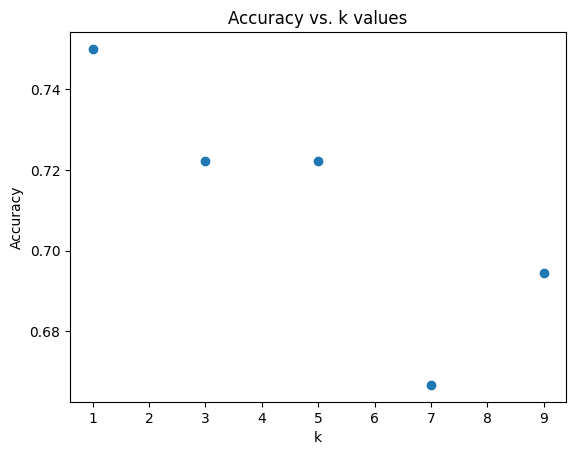

In [7]:
plt.scatter(k_values,accuracy_scores)
plt.xlabel("k")
plt.ylabel("Accuracy")
plt.title("Accuracy vs. k values")
plt.show()

In [8]:
k_values=range(1,30)
accuracy_scores=[]

for k in k_values:
    knn=KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train,y_train)
    y_pred=knn.predict(X_test)
    accuracy = accuracy_score(y_test,y_pred)
    accuracy_scores.append(accuracy)

    

best_k=k_values[accuracy_scores.index(max(accuracy_scores))]
print("Best value of k:",best_k)

Best value of k: 1


# Changing value of p

In [10]:
X, y = wine.data, wine.target
# Split the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [11]:
# Define the p values to test
p_values = [1, 2, 3, 4, 5]
# Train a KNN classifier for each value of p and record the accuracy scores
accuracy_scores = []


In [13]:
for p in p_values:
    knn = KNeighborsClassifier(n_neighbors=5, p=p) # Adjust n_neighbors as needed
    knn.fit(X_train, y_train)
    y_pred = knn.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    accuracy_scores.append(accuracy)


In [14]:
# Print the accuracy scores for each p value
print("Accuracy scores for each p value:")
for p, accuracy in zip(p_values, accuracy_scores):
    print(f"p={p}: {accuracy}")
print()


Accuracy scores for each p value:
p=1: 0.8055555555555556
p=2: 0.7222222222222222
p=3: 0.7222222222222222
p=4: 0.7222222222222222
p=5: 0.7222222222222222



# Activity 1 - 1186

In [16]:
import pandas as pd
import numpy as np

In [18]:
df = pd.read_csv("creditcard.csv")
df.head()


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [19]:
print("Dataset shape:", df.shape)
print(df["Class"].value_counts())

Dataset shape: (284807, 31)
Class
0    284315
1       492
Name: count, dtype: int64


In [20]:
X = df.drop("Class", axis=1)
y = df["Class"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (284807, 30)
Target shape: (284807,)


In [21]:
# train test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

### Applying smote

In [22]:
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE



In [23]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

smote = SMOTE(random_state=42)

X_train_resampled, y_train_resampled = smote.fit_resample(
    X_train_scaled, y_train
)

In [24]:
print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_resampled.value_counts())

Before SMOTE:
Class
0    227451
1       394
Name: count, dtype: int64

After SMOTE:
Class
0    227451
1    227451
Name: count, dtype: int64


### Train KNN with k=5

In [25]:
knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train_resampled, y_train_resampled)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


In [27]:
from sklearn.metrics import  f1_score
y_pred = knn.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

In [28]:
print("KNN Results (k=5)")
print("Accuracy:", round(accuracy, 4))
print("F1-Score:", round(f1, 4))

KNN Results (k=5)
Accuracy: 0.9978
F1-Score: 0.5831


### Tune k Using GridSearchCV

In [29]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

param_grid = {
    "n_neighbors": [3, 5, 7, 9, 11, 15]
}

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    KNeighborsClassifier(),
    param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1
)



In [31]:

grid_search.fit(X_train_resampled, y_train_resampled)

print("Best k:", grid_search.best_params_["n_neighbors"])
print("Best CV F1-Score:", round(grid_search.best_score_, 4))

Best k: 3
Best CV F1-Score: 0.9992


In [32]:
best_knn = grid_search.best_estimator_

y_pred_tuned = best_knn.predict(X_test_scaled)

tuned_accuracy = accuracy_score(y_test, y_pred_tuned)
tuned_f1 = f1_score(y_test, y_pred_tuned)


In [33]:
print("Tuned KNN Results")
print("Best k:", grid_search.best_params_["n_neighbors"])
print("Accuracy:", round(tuned_accuracy, 4))
print("F1-Score:", round(tuned_f1, 4))

Tuned KNN Results
Best k: 3
Accuracy: 0.9985
F1-Score: 0.6561


In [34]:
results = pd.DataFrame({
    "Model": ["KNN (k=5)", "Tuned KNN"],
    "Accuracy": [accuracy, tuned_accuracy],
    "F1-Score": [f1, tuned_f1]
})

print(results.to_string(index=False))

    Model  Accuracy  F1-Score
KNN (k=5)  0.997841  0.583051
Tuned KNN  0.998473  0.656126
